In [ ]:
# ============================================================
# USED VEHICLE VALUATION AND PRICE PREDICTION
# Models:
# 1. Linear Regression
# 2. Random Forest Regression
# 3. Fully Connected Neural Network (FCNN)
#
# Dataset:
# Kaggle - 10 Million Used Car Listings
#
# Designed for Google Colab
# ============================================================


# ============================================================
# 0. INSTALL REQUIRED PACKAGES
# ============================================================

!pip install -q kagglehub joblib


In [ ]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import re
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import kagglehub
import joblib

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

import tensorflow as tf


warnings.filterwarnings("ignore")
warnings.filterwarnings(
    "default",
    category=pd.errors.ParserWarning
)


In [ ]:
# ============================================================
# 2. GLOBAL SETTINGS
# ============================================================

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)


# ------------------------------------------------------------
# QUICK TEST
# ------------------------------------------------------------
# True  = test whether the whole pipeline works
# False = final assignment experiment
# ------------------------------------------------------------

QUICK_TEST = False


if QUICK_TEST:

    MAX_MODEL_ROWS = 30_000

    RF_TUNE_ROWS = 25_000

    FCNN_EPOCHS = 10

    RF_CONFIGS = [

        {
            "name": "RF_1",
            "n_estimators": 50,
            "max_depth": 20,
            "min_samples_split": 4,
            "min_samples_leaf": 2,
            "max_features": "sqrt"
        },

        {
            "name": "RF_2",
            "n_estimators": 60,
            "max_depth": 25,
            "min_samples_split": 4,
            "min_samples_leaf": 2,
            "max_features": 0.7
        },

        {
            "name": "RF_3",
            "n_estimators": 70,
            "max_depth": None,
            "min_samples_split": 4,
            "min_samples_leaf": 2,
            "max_features": 0.8
        },

        {
            "name": "RF_4",
            "n_estimators": 70,
            "max_depth": None,
            "min_samples_split": 2,
            "min_samples_leaf": 1,
            "max_features": 0.8
        }
    ]

else:

    # --------------------------------------------------------
    # FINAL RUN
    # --------------------------------------------------------

    MAX_MODEL_ROWS = 300_000

    # RF tuning is performed using part of training data
    # to avoid making 4 full 300k RF models.
    RF_TUNE_ROWS = 100_000

    FCNN_EPOCHS = 50

    RF_CONFIGS = [

    {
        "name": "RF_1",
        "n_estimators": 200,
        "max_depth": 20,
        "min_samples_split": 4,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    },

    {
        "name": "RF_2",
        "n_estimators": 300,
        "max_depth": 25,
        "min_samples_split": 4,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    },

    {
        "name": "RF_3",
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": "sqrt"
    },

    {
        "name": "RF_4",
        "n_estimators": 300,
        "max_depth": 30,
        "min_samples_split": 6,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    }
]


# ------------------------------------------------------------
# DATA LOADING SETTINGS
# ------------------------------------------------------------

CHUNK_SIZE = 250_000

# Read a percentage from every source chunk.
CHUNK_SAMPLE_FRAC = 0.05


# ------------------------------------------------------------
# CATEGORICAL FEATURE SETTINGS
# ------------------------------------------------------------

# Originally 50.
# Increased to preserve more brand/model information.
MAX_CATEGORIES_PER_FEATURE = 100

MIN_CATEGORY_FREQUENCY = 20


# Dataset is labelled as 2025 used-car listings.
REFERENCE_YEAR = 2025


print("=" * 70)
print("MODE:", "QUICK TEST" if QUICK_TEST else "FINAL RUN")
print("Maximum model rows:", MAX_MODEL_ROWS)
print("RF tuning rows:", RF_TUNE_ROWS)
print("Maximum categories:", MAX_CATEGORIES_PER_FEATURE)
print("=" * 70)


MODE: FINAL RUN
Maximum model rows: 300000
RF tuning rows: 100000
Maximum categories: 100


In [ ]:
# ============================================================
# 3. OUTPUT DIRECTORY
# ============================================================

# Keep generated files in one directory relative to the notebook.
# This works in Colab and in a local GitHub checkout.
OUTPUT_DIR = Path("used_car_results")

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory:")
print(OUTPUT_DIR.resolve())


Output directory:
/content/used_car_results


In [ ]:
# ============================================================
# 4. DOWNLOAD DATASET
# ============================================================

dataset_path = kagglehub.dataset_download(
    "zsarpong/10-million-used-car-listings"
)

print("\nDataset downloaded to:")
print(dataset_path)


100%|██████████| 277M/277M [00:03<00:00, 73.9MB/s]

Extracting files...



Dataset downloaded to:
/root/.cache/kagglehub/datasets/zsarpong/10-million-used-car-listings/versions/1


In [ ]:
# ============================================================
# 5. FIND CSV FILES
# ============================================================

csv_files = sorted(
    Path(dataset_path).rglob("*.csv")
)

print("\nCSV files found:")

for file in csv_files:
    print(file)


if len(csv_files) == 0:

    print("\nNo CSV files found.")
    print("Files available in dataset:")

    for file in Path(dataset_path).rglob("*"):
        print(file)

    raise FileNotFoundError(
        "No CSV file was found in the Kaggle dataset."
    )



CSV files found:
/root/.cache/kagglehub/datasets/zsarpong/10-million-used-car-listings/versions/1/used_cars_10M_2025.csv


In [ ]:
# ============================================================
# 6. COLUMN NORMALISATION
# ============================================================

def normalize_column_name(column):

    column = str(column).strip().lower()

    column = re.sub(
        r"[^a-z0-9]+",
        "_",
        column
    )

    column = column.strip("_")

    return column


COLUMN_ALIASES = {

    # Target
    "price": "price_usd",
    "selling_price": "price_usd",
    "listing_price": "price_usd",
    "listed_price": "price_usd",

    # Brand
    "make": "brand",
    "manufacturer": "brand",

    # Fuel
    "fuel": "fuel_type",
    "fueltype": "fuel_type",

    # Transmission
    "transmission_type": "transmission",

    # Mileage
    "miles": "mileage",
    "mileage_km": "mileage",

    # Horsepower
    "hp": "horsepower",

    # Colour
    "colour": "color",

    # Condition
    "condition": "condition_score",

    # Vehicle Type
    "body_type": "vehicle_type",
    "body_style": "vehicle_type"
}


def standardize_columns(df):

    df = df.copy()

    df.columns = [
        normalize_column_name(c)
        for c in df.columns
    ]

    rename_dict = {}

    for old_name, new_name in COLUMN_ALIASES.items():

        if (
            old_name in df.columns
            and new_name not in df.columns
        ):

            rename_dict[old_name] = new_name

    df = df.rename(
        columns=rename_dict
    )

    return df


In [ ]:
# ============================================================
# 7. LOAD DATA USING CHUNK SAMPLING
# ============================================================

sampled_chunks = []

total_rows_scanned = 0

chunk_counter = 0


TARGET_CANDIDATES = [
    "price_usd",
    "price",
    "listing_price",
    "selling_price"
]


print("\nLoading dataset using chunk sampling...")

malformed_file_count = 0


for csv_file in csv_files:

    print("\nReading:", csv_file.name)

    try:

        reader = pd.read_csv(
            csv_file,
            chunksize=CHUNK_SIZE,
            low_memory=False,
            on_bad_lines="warn"
        )

        for chunk in reader:

            chunk_counter += 1

            total_rows_scanned += len(chunk)

            chunk = standardize_columns(chunk)

            # Ignore unrelated CSV files without price column
            if not any(
                c in chunk.columns
                for c in TARGET_CANDIDATES
            ):
                continue

            sample = chunk.sample(
                frac=CHUNK_SAMPLE_FRAC,
                random_state=RANDOM_STATE + chunk_counter
            )

            sampled_chunks.append(sample)

            print(
                "Scanned:",
                f"{total_rows_scanned:,}",
                "| Sample collected:",
                f"{sum(len(x) for x in sampled_chunks):,}"
            )

    except Exception as e:

        malformed_file_count += 1

        print(
            "Could not read:",
            csv_file,
            "\nReason:",
            e
        )


if len(sampled_chunks) == 0:

    raise ValueError(
        "No usable listing data containing a price column was found."
    )


data = pd.concat(
    sampled_chunks,
    ignore_index=True
)


# Randomly reduce to modelling size
if len(data) > MAX_MODEL_ROWS:

    data = data.sample(
        n=MAX_MODEL_ROWS,
        random_state=RANDOM_STATE
    ).reset_index(drop=True)


print("\n" + "=" * 70)
print("DATA LOADING COMPLETE")
print("=" * 70)

print(
    "Source rows scanned:",
    f"{total_rows_scanned:,}"
)

print(
    "Rows used for modelling:",
    f"{len(data):,}"
)

print(
    "Files with read errors:",
    malformed_file_count
)



Loading dataset using chunk sampling...

Reading: used_cars_10M_2025.csv
Scanned: 250,000 | Sample collected: 12,500
Scanned: 500,000 | Sample collected: 25,000
Scanned: 750,000 | Sample collected: 37,500
Scanned: 1,000,000 | Sample collected: 50,000
Scanned: 1,250,000 | Sample collected: 62,500
Scanned: 1,500,000 | Sample collected: 75,000
Scanned: 1,750,000 | Sample collected: 87,500
Scanned: 2,000,000 | Sample collected: 100,000
Scanned: 2,250,000 | Sample collected: 112,500
Scanned: 2,500,000 | Sample collected: 125,000
Scanned: 2,750,000 | Sample collected: 137,500
Scanned: 3,000,000 | Sample collected: 150,000
Scanned: 3,250,000 | Sample collected: 162,500
Scanned: 3,500,000 | Sample collected: 175,000
Scanned: 3,750,000 | Sample collected: 187,500
Scanned: 4,000,000 | Sample collected: 200,000
Scanned: 4,250,000 | Sample collected: 212,500
Scanned: 4,500,000 | Sample collected: 225,000
Scanned: 4,750,000 | Sample collected: 237,500
Scanned: 5,000,000 | Sample collected: 250,000

In [ ]:
# ============================================================
# 8. INITIAL DATA INSPECTION
# ============================================================

print("\nColumn names:")

print(
    data.columns.tolist()
)


print("\nFirst five rows:")

display(
    data.head()
)


print("\nDataset information:")

data.info()


print("\nData types:")

print(
    data.dtypes
)



Column names:
['id', 'country', 'city', 'brand', 'model', 'year', 'mileage', 'price_usd', 'fuel_type', 'transmission', 'horsepower', 'doors', 'color', 'condition_score', 'days_on_market', 'is_electric']

First five rows:


,id,country,city,brand,model,year,mileage,price_usd,fuel_type,transmission,horsepower,doors,color,condition_score,days_on_market,is_electric
0,2211887,USA,Rebeccamouth,Kia,Sportage,1999,347913,1785,Hybrid,Automatic,216,5,Green,3.9,337,0
1,3937665,USA,East Craig,Honda,CR-V,2008,265036,2735,Electric,Automatic,353,4,Silver,7.7,356,0
2,2780234,USA,Lake Kathleenmouth,Chevrolet,Silverado,2021,89626,41969,Gasoline,Automatic,555,4,Red,8.4,354,0
3,2613442,USA,Rodriguezbury,Audi,Q5,2001,316466,1124,Gasoline,Automatic,590,4,Blue,2.0,264,0
4,8124193,Germany,Lippstadt,Ford,F-150,2006,312842,5370,Hybrid,Automatic,576,5,Brown,6.8,303,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               300000 non-null  int64  
 1   country          300000 non-null  object 
 2   city             300000 non-null  object 
 3   brand            300000 non-null  object 
 4   model            300000 non-null  object 
 5   year             300000 non-null  int64  
 6   mileage          300000 non-null  int64  
 7   price_usd        300000 non-null  int64  
 8   fuel_type        300000 non-null  object 
 9   transmission     300000 non-null  object 
 10  horsepower       300000 non-null  int64  
 11  doors            300000 non-null  int64  
 12  color            300000 non-null  object 
 13  condition_score  300000 non-null  float64
 14  days_on_market   300000 non-null  int64  
 15  is_electric      300000 non-null  int64  
dtypes: float64(1), i

In [ ]:
# ============================================================
# 9. TARGET VARIABLE
# ============================================================

if "price_usd" not in data.columns:

    possible_price_columns = [
        c for c in data.columns
        if "price" in c
    ]

    print(
        "\nPossible price columns:",
        possible_price_columns
    )

    raise ValueError(
        "price_usd could not be identified automatically."
    )


TARGET = "price_usd"


In [ ]:
# ============================================================
# 10. DATA CLEANING
# ============================================================

print("\n" + "=" * 70)
print("DATA CLEANING")
print("=" * 70)


# ------------------------------------------------------------
# Convert target to
# ------------------------------------------------------------

data[TARGET] = pd.to_numeric(
    data[TARGET],
    errors="coerce"
)


# ------------------------------------------------------------
# Numeric features
# ------------------------------------------------------------

possible_numeric_columns = [

    "year",
    "mileage",
    "horsepower",
    "doors",
    "condition_score",
    "days_on_market"
]


for column in possible_numeric_columns:

    if column in data.columns:

        data[column] = pd.to_numeric(
            data[column],
            errors="coerce"
        )


# ------------------------------------------------------------
# Remove invalid target values
# ------------------------------------------------------------

before = len(data)

data = data[
    data[TARGET].notna()
].copy()

data = data[
    data[TARGET] > 0
].copy()

print(
    "Rows removed because of invalid price:",
    before - len(data)
)


# ------------------------------------------------------------
# Audit exact duplicate rows and duplicate listing IDs
# ------------------------------------------------------------

exact_duplicate_count = data.duplicated().sum()

print(
    "Exact duplicate rows:",
    exact_duplicate_count
)

data = data.drop_duplicates().copy()

# ------------------------------------------------------------
# Remove duplicate listing IDs
# ------------------------------------------------------------

if "id" in data.columns:

    duplicate_count = data["id"].duplicated().sum()

    print(
        "Duplicate IDs:",
        duplicate_count
    )

    data = data.drop_duplicates(
        subset="id"
    )


# ------------------------------------------------------------
# Invalid mileage
# ------------------------------------------------------------

if "mileage" in data.columns:

    data.loc[
        data["mileage"] < 0,
        "mileage"
    ] = np.nan


# ------------------------------------------------------------
# Invalid horsepower
# ------------------------------------------------------------

if "horsepower" in data.columns:

    data.loc[
        data["horsepower"] <= 0,
        "horsepower"
    ] = np.nan


# ------------------------------------------------------------
# Invalid doors
# ------------------------------------------------------------

if "doors" in data.columns:

    data.loc[
        ~data["doors"].between(1, 8),
        "doors"
    ] = np.nan


# ------------------------------------------------------------
# Invalid year
# ------------------------------------------------------------

if "year" in data.columns:

    data.loc[
        ~data["year"].between(
            1900,
            REFERENCE_YEAR
        ),
        "year"
    ] = np.nan


print("\nMissing values:")

missing_values = (
    data.isnull()
    .sum()
    .sort_values(ascending=False)
)

print(
    missing_values[
        missing_values > 0
    ]
)



DATA CLEANING
Rows removed because of invalid price: 0
Duplicate IDs: 0

Missing values:
Series([], dtype: int64)



EXPLORATORY DATA ANALYSIS
count    300000.000000
mean      11695.797407
std       13209.258906
min         800.000000
25%        2447.000000
50%        6639.000000
75%       16357.250000
max      173542.000000
Name: price_usd, dtype: float64


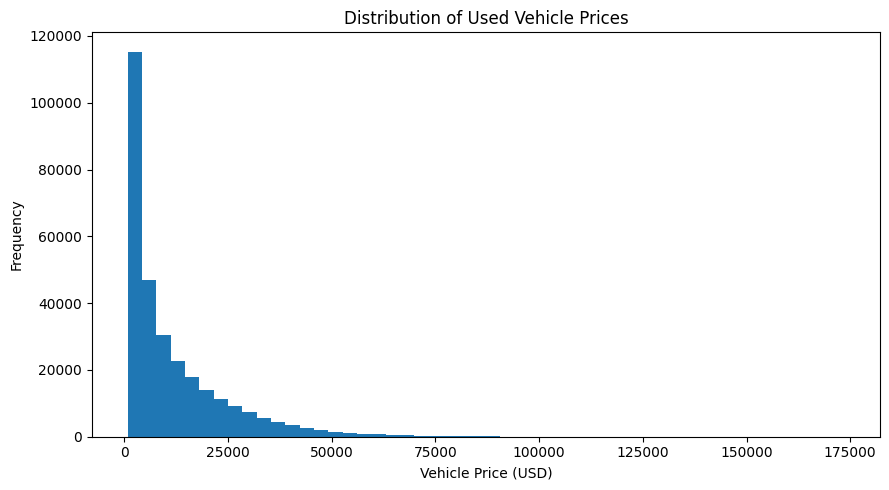


Price IQR Analysis
Q1: 2447.0
Q3: 16357.25
IQR: 13910.25
Upper bound: 37222.625
Potential price outliers: 16802
Potential price outlier percentage: 5.600666666666667

Correlation with price:
price_usd          1.000000
year               0.767347
days_on_market     0.002223
condition_score    0.001577
horsepower         0.000120
id                -0.000096
doors             -0.000372
is_electric       -0.002026
mileage           -0.782161
Name: price_usd, dtype: float64


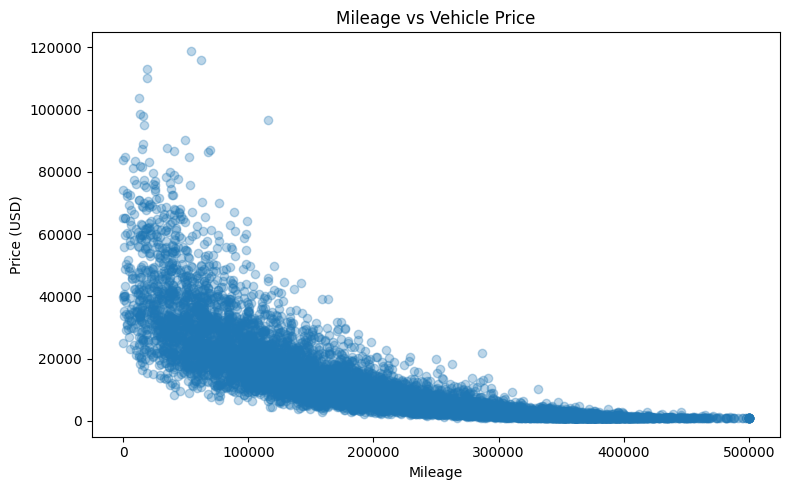

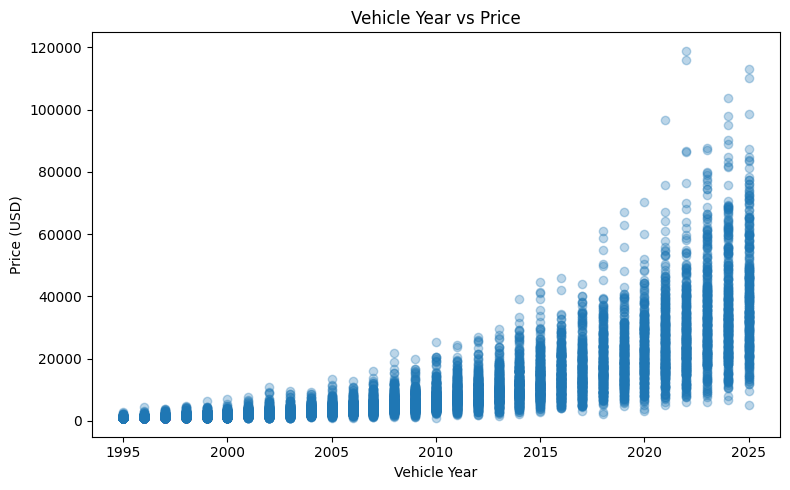

In [ ]:
# ============================================================
# 11. BASIC EDA
# ============================================================

print("\n" + "=" * 70)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 70)


print(
    data[TARGET].describe()
)


# ------------------------------------------------------------
# Price Distribution
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    data[TARGET],
    bins=50
)

plt.xlabel(
    "Vehicle Price (USD)"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Distribution of Used Vehicle Prices"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "price_distribution.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# Price IQR Outlier Analysis
# ------------------------------------------------------------

Q1 = data[TARGET].quantile(0.25)

Q3 = data[TARGET].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

price_outliers = data[
    (data[TARGET] < lower_bound)
    |
    (data[TARGET] > upper_bound)
]


print("\nPrice IQR Analysis")

print(
    "Q1:",
    Q1
)

print(
    "Q3:",
    Q3
)

print(
    "IQR:",
    IQR
)

print(
    "Upper bound:",
    upper_bound
)

print(
    "Potential price outliers:",
    len(price_outliers)
)

print(
    "Potential price outlier percentage:",
    len(price_outliers)
    /
    len(data)
    * 100
)


# NOTE:
# We DO NOT automatically delete these vehicles.
# Luxury and high-value vehicles may be legitimate observations.


# ------------------------------------------------------------
# Correlation
# ------------------------------------------------------------

numeric_for_correlation = data.select_dtypes(
    include=np.number
)


correlation_matrix = (
    numeric_for_correlation
    .corr()
)


if TARGET in correlation_matrix.columns:

    print(
        "\nCorrelation with price:"
    )

    print(
        correlation_matrix[TARGET]
        .sort_values(
            ascending=False
        )
    )


# ------------------------------------------------------------
# Scatter plots
# ------------------------------------------------------------

eda_sample = data.sample(
    n=min(
        10_000,
        len(data)
    ),
    random_state=RANDOM_STATE
)


if "mileage" in data.columns:

    plt.figure(
        figsize=(8, 5)
    )

    plt.scatter(
        eda_sample["mileage"],
        eda_sample[TARGET],
        alpha=0.3
    )

    plt.xlabel(
        "Mileage"
    )

    plt.ylabel(
        "Price (USD)"
    )

    plt.title(
        "Mileage vs Vehicle Price"
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "mileage_vs_price.png",
        dpi=300
    )

    plt.show()


if "year" in data.columns:

    plt.figure(
        figsize=(8, 5)
    )

    plt.scatter(
        eda_sample["year"],
        eda_sample[TARGET],
        alpha=0.3
    )

    plt.xlabel(
        "Vehicle Year"
    )

    plt.ylabel(
        "Price (USD)"
    )

    plt.title(
        "Vehicle Year vs Price"
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "year_vs_price.png",
        dpi=300
    )

    plt.show()


In [ ]:
# ============================================================
# 12. FEATURE ENGINEERING
# ============================================================

print("\n" + "=" * 70)
print("FEATURE ENGINEERING")
print("=" * 70)


# ------------------------------------------------------------
# Vehicle Age
# ------------------------------------------------------------

if "year" in data.columns:

    data["vehicle_age"] = (
        REFERENCE_YEAR
        -
        data["year"]
    )

    data.loc[
        data["vehicle_age"] < 0,
        "vehicle_age"
    ] = np.nan


# ------------------------------------------------------------
# Mileage Per Year
# ------------------------------------------------------------

if (
    "mileage" in data.columns
    and
    "vehicle_age" in data.columns
):

    data["mileage_per_year"] = (
        data["mileage"]
        /
        (
            data["vehicle_age"] + 1
        )
    )


# ------------------------------------------------------------
# Brand + Model Combination
# ------------------------------------------------------------

if (
    "brand" in data.columns
    and
    "model" in data.columns
):

    data["brand_model"] = np.where(

        data["brand"].notna()
        &
        data["model"].notna(),

        data["brand"].astype(str)
        +
        "_"
        +
        data["model"].astype(str),

        np.nan
    )


print(
    "Feature engineering completed."
)



FEATURE ENGINEERING
Feature engineering completed.


In [ ]:
# ============================================================
# 13. DEFINE MODEL FEATURES
# ============================================================

numeric_candidates = [
    "year",
    "vehicle_age",
    "mileage",
    "mileage_per_year",
    "horsepower",
    "doors",
    "condition_score"
]


categorical_candidates = [

    "country",

    "city",

    "brand",

    "model",

    "brand_model",

    "fuel_type",

    "transmission",

    "color",

    "vehicle_type"
]


numeric_features = [

    column

    for column
    in numeric_candidates

    if column in data.columns
]


categorical_features = [

    column

    for column
    in categorical_candidates

    if column in data.columns
]


selected_features = (

    numeric_features
    +
    categorical_features
)


print(
    "\nNumeric features:"
)

print(
    numeric_features
)


print(
    "\nCategorical features:"
)

print(
    categorical_features
)


print(
    "\nTotal number of raw predictors:",
    len(selected_features)
)


# ------------------------------------------------------------
# IMPORTANT EXCLUSIONS
# ------------------------------------------------------------

print("\nExcluded predictors:")

if "id" in data.columns:
    print("- id: identifier, not meaningful predictor")

if "days_on_market" in data.columns:
    print(
        "- days_on_market: excluded to reduce potential deployment-time leakage"
    )



Numeric features:
['year', 'vehicle_age', 'mileage', 'mileage_per_year', 'horsepower', 'doors', 'condition_score']

Categorical features:
['country', 'city', 'brand', 'model', 'brand_model', 'fuel_type', 'transmission', 'color']

Total number of raw predictors: 15

Excluded predictors:
- id: identifier, not meaningful predictor
- days_on_market: excluded to reduce potential deployment-time leakage


In [ ]:
# ============================================================
# 14. PREPARE X AND y
# ============================================================

X = data[
    selected_features
].copy()


y = data[
    TARGET
].copy()


# ------------------------------------------------------------
# Standardise categorical values as strings
# ------------------------------------------------------------

for column in categorical_features:

    X[column] = X[column].apply(

        lambda value:

        str(value)

        if pd.notna(value)

        else np.nan
    )


print(
    "\nX shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)



X shape: (300000, 15)
y shape: (300000,)


In [ ]:
# ============================================================
# 15. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# ------------------------------------------------------------
# 80% Train
# 10% Validation
# 10% Test
# ------------------------------------------------------------

# Stratify by target-price deciles so all subsets retain a similar
# price distribution while keeping the original random split design.
target_bins = pd.qcut(
    y,
    q=10,
    duplicates="drop"
)

X_train, X_temp, y_train, y_temp = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=target_bins
)


temp_target_bins = pd.qcut(
    y_temp,
    q=10,
    duplicates="drop"
)

X_validation, X_test, y_validation, y_test = train_test_split(

    X_temp,
    y_temp,

    test_size=0.50,

    random_state=RANDOM_STATE,

    stratify=temp_target_bins
)


print("Target means:")
print("Training:", y_train.mean())
print("Validation:", y_validation.mean())
print("Test:", y_test.mean())


print("\nData Split")

print(
    "Training:",
    X_train.shape
)

print(
    "Validation:",
    X_validation.shape
)

print(
    "Test:",
    X_test.shape
)



Data Split
Training: (240000, 15)
Validation: (30000, 15)
Test: (30000, 15)


In [ ]:
# ============================================================
# 16. PREPROCESSING
# ============================================================

print("\n" + "=" * 70)
print("PREPROCESSING")
print("=" * 70)


numeric_transformer = Pipeline(

    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        )
    ]
)


# ------------------------------------------------------------
# One Hot Encoder
# ------------------------------------------------------------

try:

    categorical_encoder = OneHotEncoder(

        handle_unknown="ignore",

        max_categories=MAX_CATEGORIES_PER_FEATURE,

        min_frequency=MIN_CATEGORY_FREQUENCY,

        sparse_output=False,

        dtype=np.float32
    )

except TypeError:

    categorical_encoder = OneHotEncoder(

        handle_unknown="ignore",

        max_categories=MAX_CATEGORIES_PER_FEATURE,

        min_frequency=MIN_CATEGORY_FREQUENCY,

        sparse=False,

        dtype=np.float32
    )


categorical_transformer = Pipeline(

    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        (
            "onehot",
            categorical_encoder
        )
    ]
)


preprocessor = ColumnTransformer(

    transformers=[

        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),

        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ],

    remainder="drop"
)


# ------------------------------------------------------------
# Fit ONLY using training data
# ------------------------------------------------------------

print(
    "Fitting preprocessing pipeline..."
)

X_train_processed = preprocessor.fit_transform(
    X_train
)


X_validation_processed = preprocessor.transform(
    X_validation
)


X_test_processed = preprocessor.transform(
    X_test
)


# Convert to float32 for memory efficiency
X_train_processed = np.asarray(
    X_train_processed,
    dtype=np.float32
)

X_validation_processed = np.asarray(
    X_validation_processed,
    dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed,
    dtype=np.float32
)


print(
    "\nProcessed training shape:",
    X_train_processed.shape
)

print(
    "Processed validation shape:",
    X_validation_processed.shape
)

print(
    "Processed test shape:",
    X_test_processed.shape
)



PREPROCESSING
Fitting preprocessing pipeline...

Processed training shape: (240000, 259)
Processed validation shape: (30000, 259)
Processed test shape: (30000, 259)


In [ ]:
# ============================================================
# 17. EVALUATION FUNCTION
# ============================================================

def evaluate_regression_model(
    model_name,
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    mse = mean_squared_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mse
    )

    r2 = r2_score(
        actual,
        predicted
    )

    return {

        "Model": model_name,

        "MAE": mae,

        "MSE": mse,

        "RMSE": rmse,

        "R2": r2
    }


In [ ]:
# ============================================================
# 18. MODEL 1 - MULTIPLE LINEAR REGRESSION
# ============================================================

print("\n" + "=" * 70)

print(
    "MODEL 1: MULTIPLE LINEAR REGRESSION"
)

print("=" * 70)


linear_model = LinearRegression(
    n_jobs=-1
)


linear_model.fit(
    X_train_processed,
    y_train
)


linear_validation_pred = linear_model.predict(
    X_validation_processed
)


linear_validation_result = evaluate_regression_model(

    "Linear Regression",

    y_validation,

    linear_validation_pred
)


print(
    linear_validation_result
)



MODEL 1: MULTIPLE LINEAR REGRESSION
{'Model': 'Linear Regression', 'MAE': 5470.00439453125, 'MSE': 67559184.0, 'RMSE': np.float64(8219.439396941862), 'R2': 0.6168097257614136}


In [ ]:
# ============================================================
# 19. MODEL 2 - RANDOM FOREST TUNING
# ============================================================

print("\n" + "=" * 70)

print(
    "MODEL 2: RANDOM FOREST PARAMETER EXPERIMENTS"
)

print("=" * 70)


# ------------------------------------------------------------
# Use a training subset for parameter experiments
# ------------------------------------------------------------

if len(X_train_processed) > RF_TUNE_ROWS:

    rng = np.random.default_rng(
        RANDOM_STATE
    )

    rf_tune_indices = rng.choice(

        len(X_train_processed),

        size=RF_TUNE_ROWS,

        replace=False
    )

    X_rf_tune = X_train_processed[
        rf_tune_indices
    ]

    y_rf_tune = y_train.iloc[
        rf_tune_indices
    ]

else:

    X_rf_tune = X_train_processed

    y_rf_tune = y_train


print(
    "Rows used for RF parameter tuning:",
    len(X_rf_tune)
)


rf_tuning_results = []

rf_candidate_models = {}


for config in RF_CONFIGS:

    print("\n" + "-" * 60)

    print(
        "Training:",
        config["name"]
    )

    print(
        config
    )

    print("-" * 60)


    model = RandomForestRegressor(

        n_estimators=config[
            "n_estimators"
        ],

        max_depth=config[
            "max_depth"
        ],

        min_samples_split=config[
            "min_samples_split"
        ],

        min_samples_leaf=config[
            "min_samples_leaf"
        ],

        max_features=config[
            "max_features"
        ],

        random_state=RANDOM_STATE,

        n_jobs=-1
    )


    model.fit(
        X_rf_tune,
        y_rf_tune
    )


    prediction = model.predict(
        X_validation_processed
    )


    result = evaluate_regression_model(

        config["name"],

        y_validation,

        prediction
    )


    rf_tuning_results.append(
        result
    )


    rf_candidate_models[
        config["name"]
    ] = model


    print(
        "MAE:",
        result["MAE"]
    )

    print(
        "RMSE:",
        result["RMSE"]
    )

    print(
        "R²:",
        result["R2"]
    )



MODEL 2: RANDOM FOREST PARAMETER EXPERIMENTS
Rows used for RF parameter tuning: 100000

------------------------------------------------------------
Training: RF_1
{'name': 'RF_1', 'n_estimators': 200, 'max_depth': 20, 'min_samples_split': 4, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
------------------------------------------------------------
MAE: 3904.712266035362
RMSE: 6933.165248879902
R²: 0.7273577303524704

------------------------------------------------------------
Training: RF_2
{'name': 'RF_2', 'n_estimators': 300, 'max_depth': 25, 'min_samples_split': 4, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
------------------------------------------------------------
MAE: 3831.5749895787835
RMSE: 6871.686191520923
R²: 0.7321715412164504

------------------------------------------------------------
Training: RF_3
{'name': 'RF_3', 'n_estimators': 300, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
----------------------------------------

In [ ]:
# ============================================================
# 20. RANDOM FOREST TUNING RESULTS
# ============================================================

rf_tuning_df = pd.DataFrame(
    rf_tuning_results
)


rf_tuning_df = rf_tuning_df.sort_values(
    by="MAE"
)


print("\n" + "=" * 70)

print(
    "RANDOM FOREST TUNING RESULTS"
)

print("=" * 70)


display(
    rf_tuning_df
)


rf_tuning_df.to_csv(

    OUTPUT_DIR
    /
    "random_forest_tuning.csv",

    index=False
)


# ------------------------------------------------------------
# Best configuration is selected using VALIDATION MAE
# ------------------------------------------------------------

best_rf_name = rf_tuning_df.iloc[0][
    "Model"
]


best_rf_config = next(

    config

    for config in RF_CONFIGS

    if config["name"]
    ==
    best_rf_name
)


print(
    "\nBest RF configuration:"
)

print(
    best_rf_config
)



RANDOM FOREST TUNING RESULTS


,Model,MAE,MSE,RMSE,R2
3,RF_4,3802.785111,4.692474e+07,6850.163555,0.733847
1,RF_2,3831.574990,4.722007e+07,6871.686192,0.732172
0,RF_1,3904.712266,4.806878e+07,6933.165249,0.727358
2,RF_3,3934.556512,4.823719e+07,6945.299980,0.726403



Best RF configuration:
{'name': 'RF_4', 'n_estimators': 300, 'max_depth': 30, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_features': 'sqrt'}


In [ ]:
# ============================================================
# 21. TRAIN BEST RANDOM FOREST ON FULL TRAINING SET
# ============================================================

print("\n" + "=" * 70)

print(
    "TRAINING FINAL RANDOM FOREST"
)

print("=" * 70)


random_forest_model = RandomForestRegressor(

    n_estimators=best_rf_config[
        "n_estimators"
    ],

    max_depth=best_rf_config[
        "max_depth"
    ],

    min_samples_split=best_rf_config[
        "min_samples_split"
    ],

    min_samples_leaf=best_rf_config[
        "min_samples_leaf"
    ],

    max_features=best_rf_config[
        "max_features"
    ],

    random_state=RANDOM_STATE,

    n_jobs=-1
)


random_forest_model.fit(

    X_train_processed,

    y_train
)


rf_validation_pred = random_forest_model.predict(
    X_validation_processed
)


rf_validation_result = evaluate_regression_model(

    "Random Forest",

    y_validation,

    rf_validation_pred
)


print(
    "\nFinal RF Validation Result:"
)

print(
    rf_validation_result
)



TRAINING FINAL RANDOM FOREST

Final RF Validation Result:
{'Model': 'Random Forest', 'MAE': 3764.509922772476, 'MSE': 46475355.91424853, 'RMSE': np.float64(6817.283616973004), 'R2': 0.736395506146437}



Top 20 Random Forest Features:


,Feature,Importance
2,numeric__mileage,0.351784
0,numeric__year,0.270910
1,numeric__vehicle_age,0.246491
3,numeric__mileage_per_year,0.081190
4,numeric__horsepower,0.006268
6,numeric__condition_score,0.005744
5,numeric__doors,0.001900
244,categorical__fuel_type_Gasoline,0.001012
10,categorical__country_USA,0.000970
242,categorical__fuel_type_Diesel,0.000827


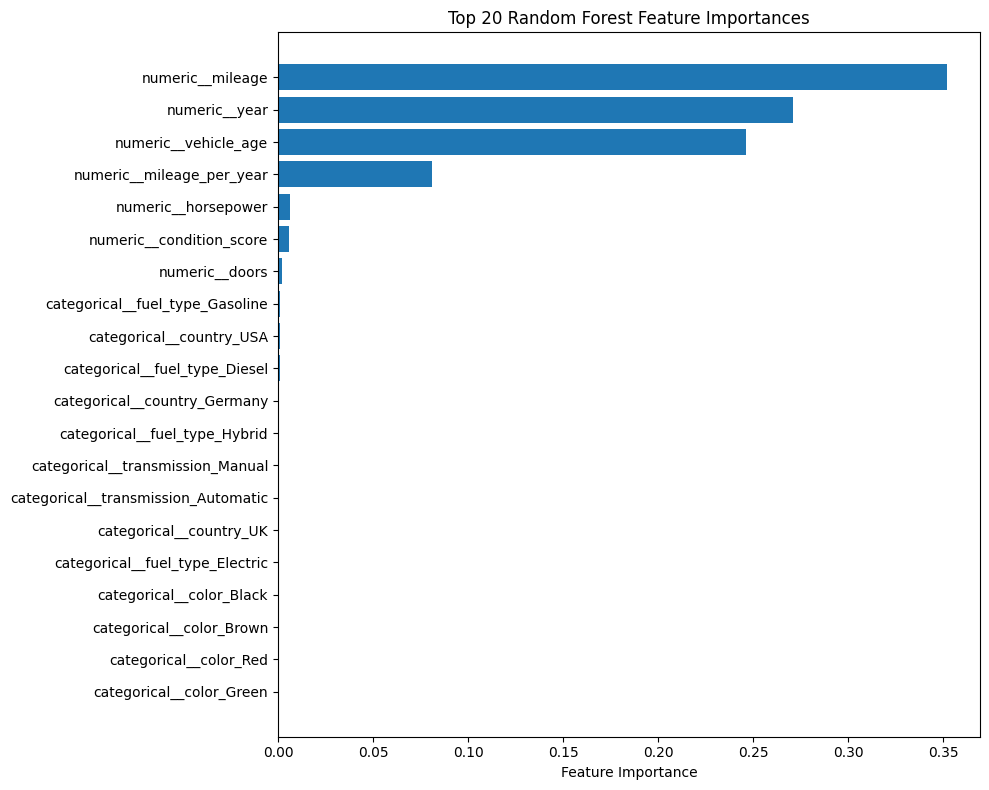

In [ ]:
# ============================================================
# 22. RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

try:

    feature_names = (
        preprocessor
        .get_feature_names_out()
    )


    feature_importance = pd.DataFrame({

        "Feature":
        feature_names,

        "Importance":
        random_forest_model
        .feature_importances_
    })


    feature_importance = (
        feature_importance
        .sort_values(
            by="Importance",
            ascending=False
        )
    )


    print(
        "\nTop 20 Random Forest Features:"
    )


    display(
        feature_importance.head(20)
    )


    feature_importance.to_csv(

        OUTPUT_DIR
        /
        "random_forest_feature_importance.csv",

        index=False
    )


    top_features = (
        feature_importance
        .head(20)
        .sort_values(
            by="Importance"
        )
    )


    plt.figure(
        figsize=(10, 8)
    )


    plt.barh(

        top_features[
            "Feature"
        ],

        top_features[
            "Importance"
        ]
    )


    plt.xlabel(
        "Feature Importance"
    )

    plt.title(
        "Top 20 Random Forest Feature Importances"
    )

    plt.tight_layout()


    plt.savefig(

        OUTPUT_DIR
        /
        "random_forest_feature_importance.png",

        dpi=300
    )


    plt.show()


except Exception as e:

    print(
        "Feature importance plot could not be generated:",
        e
    )


In [ ]:
# ============================================================
# 23. MODEL 3 - FCNN
# ============================================================

print("\n" + "=" * 70)

print(
    "MODEL 3: FULLY CONNECTED NEURAL NETWORK"
)

print("=" * 70)


# ------------------------------------------------------------
# Scale target for more stable neural network training
# ------------------------------------------------------------

target_scaler = StandardScaler()


y_train_scaled = (
    target_scaler
    .fit_transform(
        np.array(
            y_train
        ).reshape(-1, 1)
    )
    .flatten()
)


y_validation_scaled = (
    target_scaler
    .transform(
        np.array(
            y_validation
        ).reshape(-1, 1)
    )
    .flatten()
)


input_dimension = (
    X_train_processed.shape[1]
)


print(
    "FCNN input dimensions:",
    input_dimension
)


# ------------------------------------------------------------
# FCNN Architecture
# ------------------------------------------------------------

fcnn_model = Sequential([

    Input(
        shape=(
            input_dimension,
        )
    ),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(
        0.20
    ),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(
        0.10
    ),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        1,
        activation="linear"
    )
])


fcnn_model.compile(

    optimizer=Adam(
        learning_rate=0.001
    ),

    loss="mse",

    metrics=[
        "mae"
    ]
)


fcnn_model.summary()


# ------------------------------------------------------------
# Early Stopping
# ------------------------------------------------------------

early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=6,

    restore_best_weights=True,

    verbose=1
)


# ------------------------------------------------------------
# Learning Rate Reduction
# ------------------------------------------------------------

reduce_learning_rate = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=0.00001,

    verbose=1
)


# ------------------------------------------------------------
# Train FCNN
# ------------------------------------------------------------

history = fcnn_model.fit(

    X_train_processed,

    y_train_scaled,

    validation_data=(

        X_validation_processed,

        y_validation_scaled
    ),

    epochs=FCNN_EPOCHS,

    batch_size=512,

    callbacks=[

        early_stopping,

        reduce_learning_rate
    ],

    verbose=1
)



MODEL 3: FULLY CONNECTED NEURAL NETWORK
FCNN input dimensions: 259


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        33,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,649 (170.50 KB)

 Trainable params: 43,649 (170.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.3110 - mae: 0.3259 - val_loss: 0.2772 - val_mae: 0.2925 - learning_rate: 0.0010
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.2767 - mae: 0.2977 - val_loss: 0.2737 - val_mae: 0.2963 - learning_rate: 0.0010
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.2721 - mae: 0.2938 - val_loss: 0.2728 - val_mae: 0.2988 - learning_rate: 0.0010
Epoch 4/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.2697 - mae: 0.2918 - val_loss: 0.2716 - val_mae: 0.2962 - learning_rate: 0.0010
Epoch 5/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.2679 - mae: 0.2901 - val_loss: 0.2717 - val_mae: 0.2952 - learning_rate: 0.0010
Epoch 6/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.2664 - mae: 0.2893 - val_loss: 0.2733 - val_mae: 0.2958 - learning_rate: 0.0010
Epoch 7/50
465/469 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2666 - mae: 0.2896
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.00050000002

In [ ]:
# ============================================================
# 24. FCNN VALIDATION PREDICTIONS
# ============================================================

fcnn_validation_scaled_pred = (
    fcnn_model.predict(
        X_validation_processed,
        verbose=0
    )
)


fcnn_validation_pred = (
    target_scaler
    .inverse_transform(
        fcnn_validation_scaled_pred
    )
    .flatten()
)


fcnn_validation_result = evaluate_regression_model(

    "FCNN",

    y_validation,

    fcnn_validation_pred
)


print(
    "\nFCNN Validation Result:"
)

print(
    fcnn_validation_result
)



FCNN Validation Result:
{'Model': 'FCNN', 'MAE': 3901.787109375, 'MSE': 47116356.0, 'RMSE': np.float64(6864.135488173292), 'R2': 0.7327597737312317}


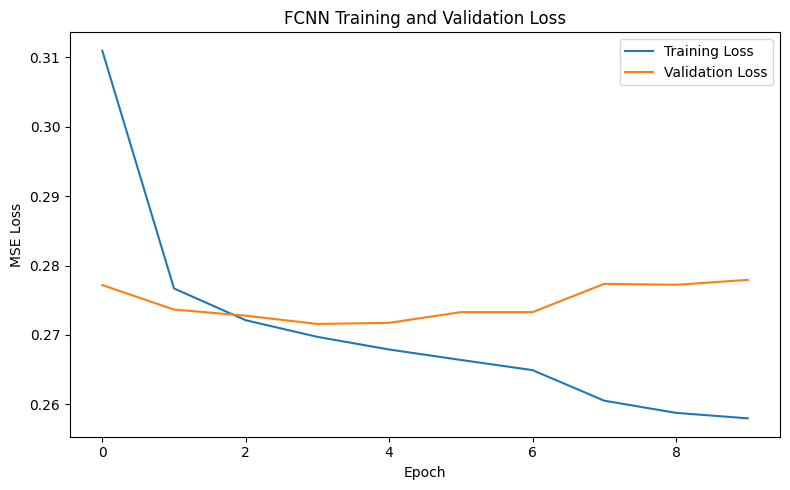

In [ ]:
# ============================================================
# 25. FCNN TRAINING HISTORY
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    history.history[
        "loss"
    ],
    label="Training Loss"
)


plt.plot(
    history.history[
        "val_loss"
    ],
    label="Validation Loss"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "MSE Loss"
)

plt.title(
    "FCNN Training and Validation Loss"
)

plt.legend()

plt.tight_layout()


plt.savefig(

    OUTPUT_DIR
    /
    "fcnn_training_history.png",

    dpi=300
)


plt.show()


In [ ]:
# ============================================================
# 26. VALIDATION MODEL COMPARISON
# ============================================================

validation_results = pd.DataFrame([

    linear_validation_result,

    rf_validation_result,

    fcnn_validation_result
])


validation_results = (
    validation_results
    .sort_values(
        by="MAE"
    )
)


print("\n" + "=" * 70)

print(
    "VALIDATION PERFORMANCE"
)

print("=" * 70)


display(
    validation_results
)


validation_results.to_csv(

    OUTPUT_DIR
    /
    "validation_performance.csv",

    index=False
)



VALIDATION PERFORMANCE


,Model,MAE,MSE,RMSE,R2
1,Random Forest,3764.509923,4.647536e+07,6817.283617,0.736396
2,FCNN,3901.787109,4.711636e+07,6864.135488,0.732760
0,Linear Regression,5470.004395,6.755918e+07,8219.439397,0.616810


In [ ]:
# ============================================================
# 27. SELECT BEST MODEL USING VALIDATION MAE
# ============================================================

best_model_name = (
    validation_results
    .iloc[0]["Model"]
)


print(
    "\nBest model based on Validation MAE:"
)

print(
    best_model_name
)



Best model based on Validation MAE:
Random Forest


In [ ]:
# ============================================================
# 28. FINAL TEST SET EVALUATION
# ============================================================

print("\n" + "=" * 70)

print(
    "FINAL TEST SET EVALUATION"
)

print("=" * 70)


# ------------------------------------------------------------
# Linear Regression
# ------------------------------------------------------------

linear_test_pred = linear_model.predict(
    X_test_processed
)


linear_test_result = evaluate_regression_model(

    "Linear Regression",

    y_test,

    linear_test_pred
)


# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------

rf_test_pred = random_forest_model.predict(
    X_test_processed
)


rf_test_result = evaluate_regression_model(

    "Random Forest",

    y_test,

    rf_test_pred
)


# ------------------------------------------------------------
# FCNN
# ------------------------------------------------------------

fcnn_test_scaled_pred = (
    fcnn_model.predict(
        X_test_processed,
        verbose=0
    )
)


fcnn_test_pred = (
    target_scaler
    .inverse_transform(
        fcnn_test_scaled_pred
    )
    .flatten()
)


fcnn_test_result = evaluate_regression_model(

    "FCNN",

    y_test,

    fcnn_test_pred
)



FINAL TEST SET EVALUATION


In [ ]:
# ============================================================
# 29. FINAL TEST PERFORMANCE TABLE
# ============================================================

test_results = pd.DataFrame([

    linear_test_result,

    rf_test_result,

    fcnn_test_result
])


test_results = (
    test_results
    .sort_values(
        by="MAE"
    )
)


print("\n" + "=" * 70)

print(
    "FINAL TEST PERFORMANCE"
)

print("=" * 70)


display(
    test_results
)


test_results.to_csv(

    OUTPUT_DIR
    /
    "test_performance.csv",

    index=False
)



FINAL TEST PERFORMANCE


,Model,MAE,MSE,RMSE,R2
1,Random Forest,3781.622115,4.751379e+07,6893.024648,0.736897
2,FCNN,3921.837891,4.822134e+07,6944.158984,0.732979
0,Linear Regression,5505.106445,6.936577e+07,8328.611409,0.615894


In [ ]:
# ============================================================
# 30. TEST PREDICTIONS TABLE
# ============================================================

prediction_table = pd.DataFrame({

    "Actual_Price":
    np.array(
        y_test
    ),

    "Linear_Regression_Prediction":
    linear_test_pred,

    "Random_Forest_Prediction":
    rf_test_pred,

    "FCNN_Prediction":
    fcnn_test_pred
})


print(
    "\nExample predictions:"
)


display(
    prediction_table.head(20)
)


prediction_table.to_csv(

    OUTPUT_DIR
    /
    "test_predictions.csv",

    index=False
)



Example predictions:


,Actual_Price,Linear_Regression_Prediction,Random_Forest_Prediction,FCNN_Prediction
0,6112,4742.577637,3623.902831,4681.683594
1,9153,16965.933594,12277.751914,13242.812500
2,1362,4516.834473,3166.640780,4096.526855
3,7349,10828.487305,6188.972162,6065.566895
4,3223,1553.921875,2833.499622,3365.144531
5,1513,2487.206055,2676.889240,3425.178711
6,5926,11280.223633,6976.337514,6652.939453
7,12788,17148.699219,13973.179089,13309.172852
8,5117,10028.362305,5789.515954,6737.454590
9,21022,21905.625000,21427.238962,20233.285156


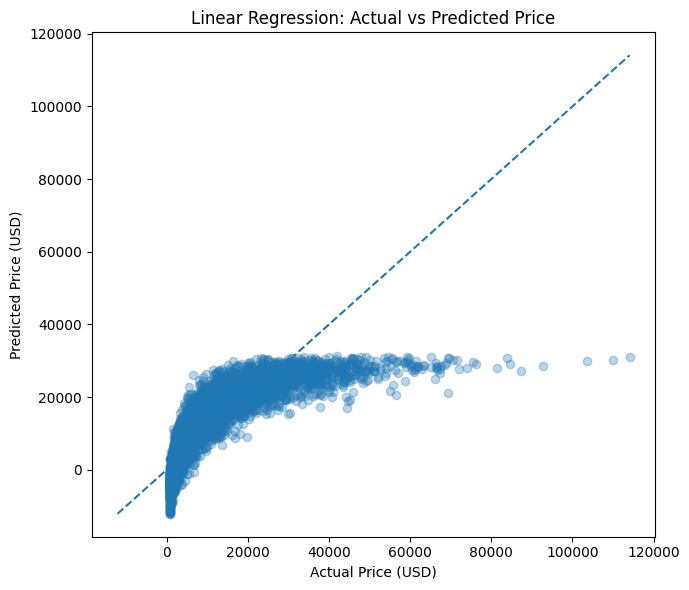

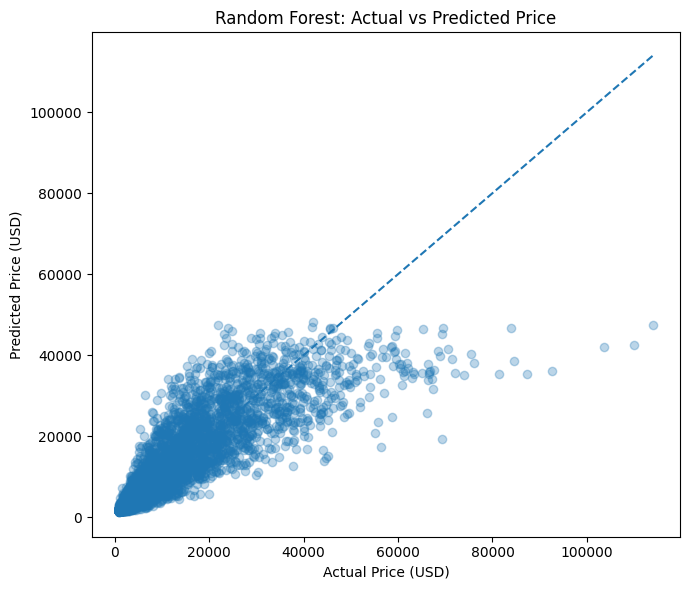

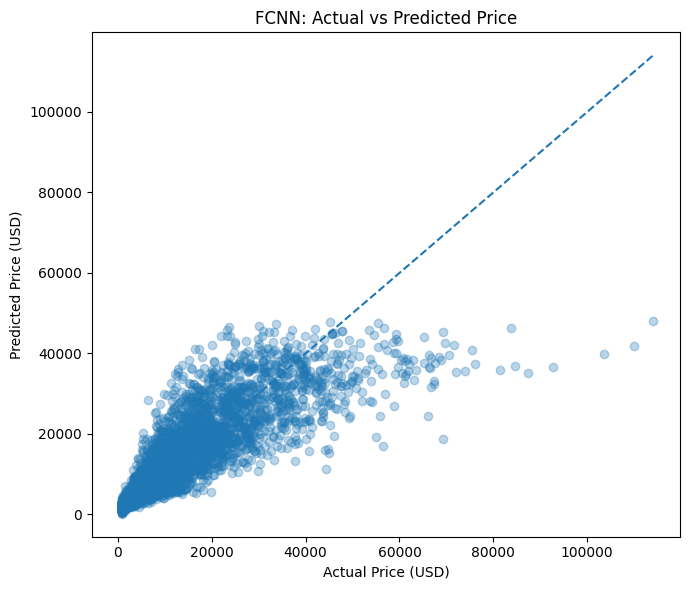

In [ ]:
# ============================================================
# 31. ACTUAL VS PREDICTED PLOTS
# ============================================================

plot_size = min(
    5000,
    len(y_test)
)


rng = np.random.default_rng(
    RANDOM_STATE
)


plot_indices = rng.choice(

    len(y_test),

    size=plot_size,

    replace=False
)


actual_plot = np.array(
    y_test
)[plot_indices]


prediction_sets = {

    "Linear Regression":
    linear_test_pred[
        plot_indices
    ],

    "Random Forest":
    rf_test_pred[
        plot_indices
    ],

    "FCNN":
    fcnn_test_pred[
        plot_indices
    ]
}


for name, predictions in prediction_sets.items():

    plt.figure(
        figsize=(7, 6)
    )

    plt.scatter(

        actual_plot,

        predictions,

        alpha=0.30
    )


    minimum_value = min(

        actual_plot.min(),

        predictions.min()
    )


    maximum_value = max(

        actual_plot.max(),

        predictions.max()
    )


    plt.plot(

        [
            minimum_value,
            maximum_value
        ],

        [
            minimum_value,
            maximum_value
        ],

        linestyle="--"
    )


    plt.xlabel(
        "Actual Price (USD)"
    )

    plt.ylabel(
        "Predicted Price (USD)"
    )

    plt.title(
        f"{name}: Actual vs Predicted Price"
    )

    plt.tight_layout()


    file_name = (
        name.lower()
        .replace(
            " ",
            "_"
        )
        +
        "_actual_vs_predicted.png"
    )


    plt.savefig(

        OUTPUT_DIR
        /
        file_name,

        dpi=300
    )


    plt.show()


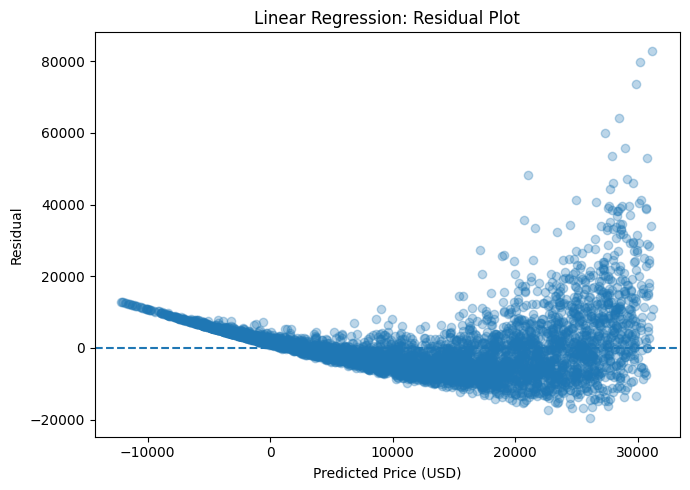

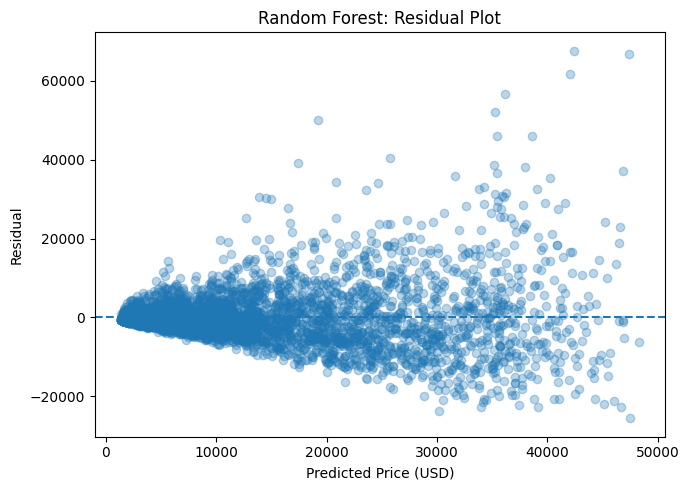

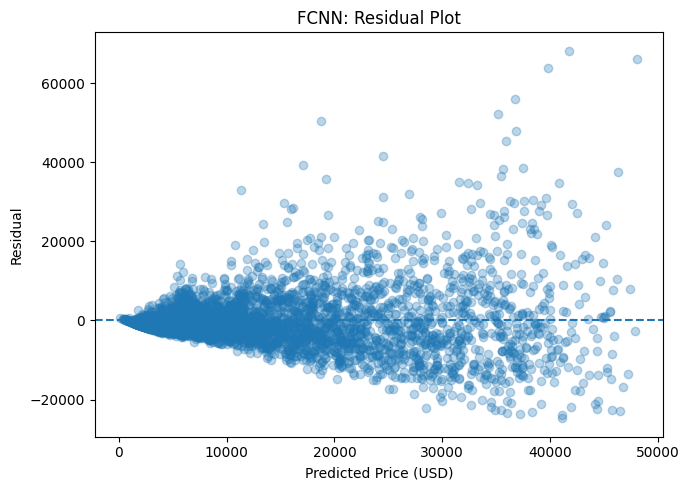

In [ ]:
# ============================================================
# 32. RESIDUAL PLOTS
# ============================================================

for name, predictions in prediction_sets.items():

    residuals = (
        actual_plot
        -
        predictions
    )


    plt.figure(
        figsize=(7, 5)
    )


    plt.scatter(

        predictions,

        residuals,

        alpha=0.30
    )


    plt.axhline(
        y=0,
        linestyle="--"
    )


    plt.xlabel(
        "Predicted Price (USD)"
    )

    plt.ylabel(
        "Residual"
    )

    plt.title(
        f"{name}: Residual Plot"
    )

    plt.tight_layout()


    file_name = (

        name.lower()
        .replace(
            " ",
            "_"
        )

        +
        "_residual_plot.png"
    )


    plt.savefig(

        OUTPUT_DIR
        /
        file_name,

        dpi=300
    )


    plt.show()


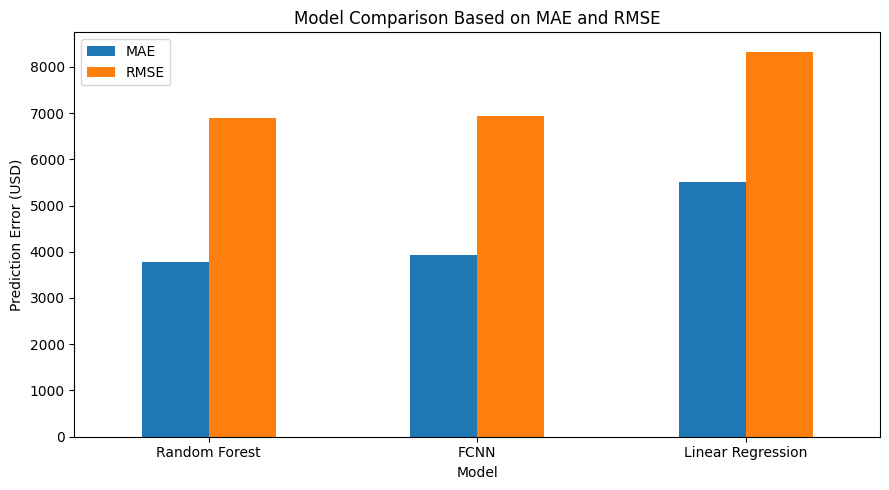

In [ ]:
# ============================================================
# 33. MODEL PERFORMANCE COMPARISON - MAE AND RMSE
# ============================================================

performance_plot = (

    test_results

    .set_index(
        "Model"
    )
)


ax = performance_plot[
    [
        "MAE",
        "RMSE"
    ]
].plot(

    kind="bar",

    figsize=(
        9,
        5
    )
)


ax.set_ylabel(
    "Prediction Error (USD)"
)

ax.set_title(
    "Model Comparison Based on MAE and RMSE"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()


plt.savefig(

    OUTPUT_DIR
    /
    "model_error_comparison.png",

    dpi=300
)


plt.show()


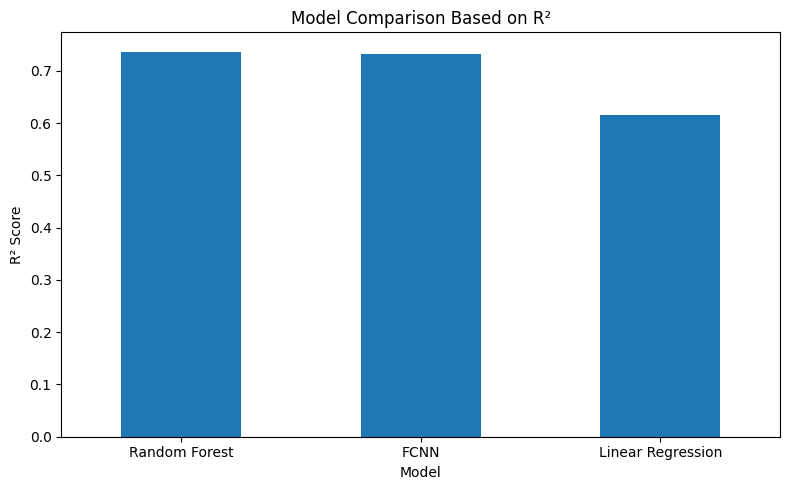

In [ ]:
# ============================================================
# 34. MODEL PERFORMANCE COMPARISON - R2
# ============================================================

ax = performance_plot[
    "R2"
].plot(

    kind="bar",

    figsize=(
        8,
        5
    )
)


ax.set_ylabel(
    "R² Score"
)

ax.set_title(
    "Model Comparison Based on R²"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()


plt.savefig(

    OUTPUT_DIR
    /
    "model_r2_comparison.png",

    dpi=300
)


plt.show()


In [ ]:
# ============================================================
# 35. SAVE TRAINED MODELS
# ============================================================

print("\nSaving trained models...")


joblib.dump(

    preprocessor,

    OUTPUT_DIR
    /
    "preprocessor.joblib"
)


joblib.dump(

    linear_model,

    OUTPUT_DIR
    /
    "linear_regression_model.joblib"
)


joblib.dump(

    random_forest_model,

    OUTPUT_DIR
    /
    "random_forest_model.joblib"
)


joblib.dump(

    target_scaler,

    OUTPUT_DIR
    /
    "fcnn_target_scaler.joblib"
)


# Save the exact feature contract used during training so inference cannot
# silently drift from the training schema.
model_metadata = {
    "selected_features": selected_features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "reference_year": REFERENCE_YEAR,
    "processed_feature_names": list(
        preprocessor.get_feature_names_out()
    )
}

joblib.dump(

    model_metadata,

    OUTPUT_DIR
    /
    "model_metadata.joblib"
)


fcnn_model.save(

    OUTPUT_DIR
    /
    "fcnn_model.keras"
)


print(
    "Models successfully saved."
)



Saving trained models...
Models successfully saved.


In [ ]:
# ============================================================
# 36. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)

print(
    "FINAL PROJECT SUMMARY"
)

print("=" * 70)


print(
    "\nNumber of source rows scanned:",
    f"{total_rows_scanned:,}"
)


print(
    "Number of rows used for modelling:",
    f"{len(data):,}"
)


print(
    "\nTraining rows:",
    f"{len(X_train):,}"
)


print(
    "Validation rows:",
    f"{len(X_validation):,}"
)


print(
    "Test rows:",
    f"{len(X_test):,}"
)


print(
    "\nNumber of processed model features:",
    X_train_processed.shape[1]
)


print(
    "\nRandom Forest configuration selected:"
)

print(
    best_rf_config
)


print(
    "\nValidation results:"
)

display(
    validation_results
)


print(
    "\nFinal test results:"
)

display(
    test_results
)


print(
    "\nBest model selected using Validation MAE:"
)

print(
    best_model_name
)


print(
    "\nAll outputs have been saved to:"
)

print(
    OUTPUT_DIR
)


print("\n" + "=" * 70)

print(
    "PROGRAM COMPLETED SUCCESSFULLY"
)

print("=" * 70)



FINAL PROJECT SUMMARY

Number of source rows scanned: 10,000,000
Number of rows used for modelling: 300,000

Training rows: 240,000
Validation rows: 30,000
Test rows: 30,000

Number of processed model features: 259

Random Forest configuration selected:
{'name': 'RF_4', 'n_estimators': 300, 'max_depth': 30, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_features': 'sqrt'}

Validation results:


,Model,MAE,MSE,RMSE,R2
1,Random Forest,3764.509923,4.647536e+07,6817.283617,0.736396
2,FCNN,3901.787109,4.711636e+07,6864.135488,0.732760
0,Linear Regression,5470.004395,6.755918e+07,8219.439397,0.616810



Final test results:


,Model,MAE,MSE,RMSE,R2
1,Random Forest,3781.622115,4.751379e+07,6893.024648,0.736897
2,FCNN,3921.837891,4.822134e+07,6944.158984,0.732979
0,Linear Regression,5505.106445,6.936577e+07,8328.611409,0.615894



Best model selected using Validation MAE:
Random Forest

All outputs have been saved to:
/content/used_car_results

PROGRAM COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# INTERACTIVE PRICE PREDICTION WINDOW
# ============================================================
# Loads the three trained models and the saved feature contract. The
# prediction inputs are checked against the features used during training.

import joblib
import numpy as np
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path

from tensorflow.keras.models import load_model


# Make the prediction section runnable in a fresh notebook session.
OUTPUT_DIR = Path("used_car_results")
MODEL_DIR = OUTPUT_DIR

try:
    preprocessor
    linear_model
    random_forest_model
    fcnn_model
    target_scaler
    model_metadata
    print("Using models already in memory from this session.")
except NameError:
    print("Loading saved models from disk...")

    preprocessor = joblib.load(
        MODEL_DIR / "preprocessor.joblib"
    )
    linear_model = joblib.load(
        MODEL_DIR / "linear_regression_model.joblib"
    )
    random_forest_model = joblib.load(
        MODEL_DIR / "random_forest_model.joblib"
    )
    target_scaler = joblib.load(
        MODEL_DIR / "fcnn_target_scaler.joblib"
    )
    model_metadata = joblib.load(
        MODEL_DIR / "model_metadata.joblib"
    )
    fcnn_model = load_model(
        MODEL_DIR / "fcnn_model.keras"
    )

    print("Models loaded.")


selected_features = model_metadata["selected_features"]
numeric_features = model_metadata["numeric_features"]
categorical_features = model_metadata["categorical_features"]
REFERENCE_YEAR = model_metadata["reference_year"]


In [ ]:
# ------------------------------------------------------------
# CATEGORY OPTIONS
# ------------------------------------------------------------
# Pulled from the categories the OneHotEncoder learned during
# training, so the dropdowns only ever offer values the models
# actually know about.

ohe = preprocessor.named_transformers_["categorical"].named_steps["onehot"]
cat_cols = categorical_features
learned_categories = dict(zip(cat_cols, ohe.categories_))

BRAND_MODEL_MAP = {}
for combo in learned_categories["brand_model"]:
    brand, separator, model = combo.partition("_")
    if separator:
        BRAND_MODEL_MAP.setdefault(brand, []).append(model)

# ------------------------------------------------------------
# WIDGETS
# ------------------------------------------------------------
w_country = widgets.Dropdown(options=sorted(learned_categories["country"]),
                              description="Country:")
w_city = widgets.Text(value="Aachen", description="City:",
                       placeholder="e.g. Aachen")
w_brand = widgets.Dropdown(options=sorted(BRAND_MODEL_MAP.keys()),
                            description="Brand:")
w_model = widgets.Dropdown(options=sorted(BRAND_MODEL_MAP[w_brand.value]),
                            description="Model:")
w_fuel = widgets.Dropdown(options=sorted(learned_categories["fuel_type"]),
                           description="Fuel type:")
w_transmission = widgets.Dropdown(options=sorted(learned_categories["transmission"]),
                                   description="Transmission:")
w_color = widgets.Dropdown(options=sorted(learned_categories["color"]),
                            description="Color:")

w_year = widgets.IntSlider(value=2019, min=1990, max=REFERENCE_YEAR,
                            step=1, description="Year:")
w_mileage = widgets.IntText(value=45000, description="Mileage:")
w_horsepower = widgets.IntSlider(value=180, min=60, max=700, step=5,
                                  description="Horsepower:")
w_doors = widgets.Dropdown(options=[2, 3, 4, 5], value=4, description="Doors:")
w_condition = widgets.IntSlider(value=7, min=1, max=10, step=1,
                                 description="Condition:")

predict_button = widgets.Button(description="Predict Price",
                                 button_style="success",
                                 icon="calculator")
output_box = widgets.Output()


def on_brand_change(change):
    """Keep the model dropdown in sync with the chosen brand."""
    new_models = sorted(BRAND_MODEL_MAP[change["new"]])
    w_model.options = new_models
    w_model.value = new_models[0]


w_brand.observe(on_brand_change, names="value")


def predict_price(_button):
    with output_box:
        clear_output()

        vehicle_age = REFERENCE_YEAR - w_year.value
        mileage_per_year = w_mileage.value / (vehicle_age + 1)
        brand_model = f"{w_brand.value}_{w_model.value}"

        row = {
            "year": w_year.value,
            "vehicle_age": vehicle_age,
            "mileage": w_mileage.value,
            "mileage_per_year": mileage_per_year,
            "horsepower": w_horsepower.value,
            "doors": w_doors.value,
            "condition_score": w_condition.value,
            "country": w_country.value,
            "city": w_city.value,
            "brand": w_brand.value,
            "model": w_model.value,
            "brand_model": brand_model,
            "fuel_type": w_fuel.value,
            "transmission": w_transmission.value,
            "color": w_color.value,
        }

        missing_features = [
            feature
            for feature in selected_features
            if feature not in row
        ]

        if missing_features:
            raise ValueError(
                "Prediction input is missing training features: "
                + ", ".join(missing_features)
            )

        X_input = pd.DataFrame([
            {feature: row[feature] for feature in selected_features}
        ])

        X_processed = preprocessor.transform(X_input)

        linear_pred = linear_model.predict(X_processed)[0]
        rf_pred = random_forest_model.predict(X_processed)[0]
        fcnn_scaled_pred = fcnn_model.predict(X_processed, verbose=0)
        fcnn_pred = target_scaler.inverse_transform(fcnn_scaled_pred).flatten()[0]

        results = pd.DataFrame([
            {"Model": "Linear Regression", "Predicted Price (USD)": round(linear_pred, 2)},
            {"Model": "Random Forest", "Predicted Price (USD)": round(rf_pred, 2)},
            {"Model": "FCNN", "Predicted Price (USD)": round(fcnn_pred, 2)},
        ])

        print("Vehicle summary:")
        print(f"  {w_year.value} {w_brand.value} {w_model.value} | "
              f"{w_mileage.value:,} mi | {w_horsepower.value} hp | "
              f"{w_fuel.value} | {w_transmission.value} | "
              f"{w_doors.value}-door | {w_color.value} | "
              f"condition {w_condition.value}/10 | {w_city.value}, {w_country.value}")
        print()
        display(results)
        print()
        avg_price = results["Predicted Price (USD)"].mean()
        print(f"Average of the three models: ${avg_price:,.2f}")


predict_button.on_click(predict_price)

form = widgets.VBox([
    widgets.HTML("<h3>Used Vehicle Price Predictor</h3>"),
    widgets.HBox([w_country, w_city]),
    widgets.HBox([w_brand, w_model]),
    widgets.HBox([w_fuel, w_transmission, w_color]),
    w_year,
    w_mileage,
    w_horsepower,
    w_doors,
    w_condition,
    predict_button,
    output_box,
])

display(form)
